In [1]:
import numpy as np
from matplotlib import pyplot as plt

import glob
import tqdm
from colossus.cosmology import cosmology
from colossus.lss import mass_function

# Set cosmology (Planck 2018)
cosmo=cosmology.setCosmology('planck18')

#let's use multiprocessing
from multiprocess import Pool, freeze_support, cpu_count
from functools import partial

from scipy import integrate
from scipy.stats import norm, multivariate_normal, truncnorm, poisson


from nautilus import Prior
from nautilus import Sampler

from astropy.cosmology import FlatLambdaCDM, Planck18 
import astropy.units as u
from astropy import constants
from astropy import table
import galsim

import xlensing

Lookup tables loaded!


## Generative Model for Clusters

### Mass-Richness Relation

In [2]:
#####mass obs
def mass_lambda_McClintock18(Lambda,z):
  #pivots
  log10Lambda0 = np.log10(40)
  log10z0 = np.log10(0.35)
  log10M0 = 14.489
  #scalings
  Flambda = 1.356
  Gz = -0.30
    
  mlog10M200 = log10M0 + Flambda*(np.log10(Lambda)-log10Lambda0) + Gz*(np.log10(z) - log10z0)
    
  return mlog10M200

### Cluster Mass Function

Sampled 1000 cluster masses
Mass range: 1.00e+13 - 9.03e+14 M_sun
Mean mass: 3.73e+13 M_sun
Median mass: 1.94e+13 M_sun


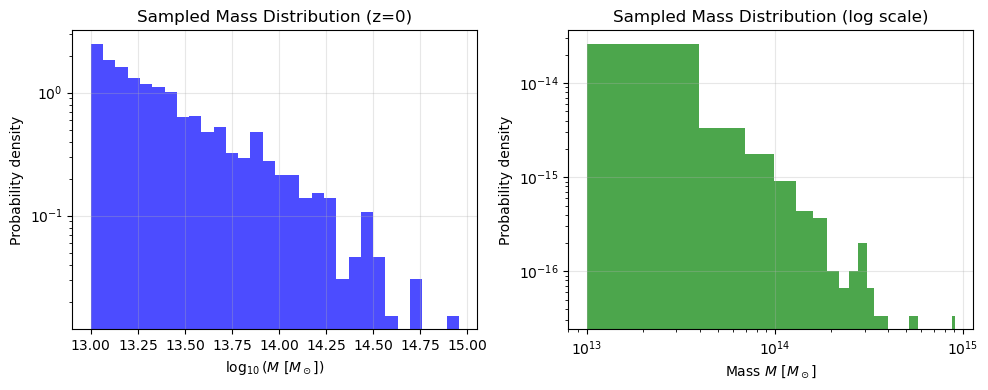

In [3]:
import numpy as np
from scipy.interpolate import interp1d
import matplotlib.pyplot as plt

def sample_colossus_masses(redshift=0, m_min=1e13, m_max=1e15, n_samples=1000, 
                           model='tinker08', mdef='200m', resolution=1000):
    """
    Sample cluster masses from Colossus mass function.
    
    Parameters:
    -----------
    redshift : float
        Redshift at which to sample
    m_min, m_max : float
        Mass range in M_sun (not M_sun/h)
    n_samples : int
        Number of masses to sample
    model : str
        Mass function model ('tinker08', 'warren', 'jenkins', etc.)
    mdef : str
        Mass definition ('200m', '200c', '500c', etc.)
    resolution : int
        Number of points for CDF interpolation
    
    Returns:
    --------
    masses : array
        Sampled masses in M_sun
    """

    
    # Convert mass to M_sun/h for Colossus internal calculations
    h = cosmo.H0 / 100.0  # Hubble parameter
    m_min_h = m_min * h
    m_max_h = m_max * h
    
    # Create mass grid in M_sun/h
    masses_h = np.logspace(np.log10(m_min_h), np.log10(m_max_h), resolution)
    
    # Get dndlnM from Colossus, then convert to dndM
    # Note: massFunction returns dndlnM when q_out='dndlnM'
    dndlnM = mass_function.massFunction(masses_h, redshift, mdef=mdef, 
                                         model=model, q_out='dndlnM')
    dndM = dndlnM / masses_h  # Convert to dndM in (Mpc/h)^-3 M_sun^-1 h
    
    # Compute number in each bin and normalize to get PDF
    dm = np.diff(np.log(masses_h))  # dlnM
    counts = dndM[:-1] * masses_h[:-1] * dm  # dndM * dM = dndlnM * dlnM
    pdf = counts / np.sum(counts)
    
    # Build CDF and interpolate (in physical masses, M_sun)
    masses_phys = masses_h[:-1] / h
    cdf = np.cumsum(pdf)
    cdf = np.insert(cdf, 0, 0)
    masses_phys = np.insert(masses_phys, 0, masses_phys[0])
    
    inv_cdf = interp1d(cdf, masses_phys, kind='linear', 
                       bounds_error=False, fill_value=(masses_phys[0], masses_phys[-1]))
    
    # Sample using inverse transform
    u = np.random.uniform(0, 1, n_samples)
    samples = inv_cdf(u)
    
    return samples

# Example usage
if __name__ == "__main__":
    # Set random seed for reproducibility
    np.random.seed(42)
    
    # Sample 1000 cluster masses at z=0
    masses = sample_colossus_masses(redshift=0, n_samples=1000)
    
    print(f"Sampled {len(masses)} cluster masses")
    print(f"Mass range: {masses.min():.2e} - {masses.max():.2e} M_sun")
    print(f"Mean mass: {masses.mean():.2e} M_sun")
    print(f"Median mass: {np.median(masses):.2e} M_sun")
    
    # Plot histogram
    plt.figure(figsize=(10, 4))
    
    plt.subplot(1, 2, 1)
    plt.hist(np.log10(masses), bins=30, density=True, alpha=0.7, color='blue')
    plt.xlabel(r'$\log_{10}(M\ [M_\odot])$')
    plt.ylabel('Probability density')
    plt.title('Sampled Mass Distribution (z=0)')
    plt.yscale('log')
    plt.grid(True, alpha=0.3)
    
    plt.subplot(1, 2, 2)
    plt.hist(masses, bins=30, density=True, alpha=0.7, color='green')
    plt.xscale('log')
    plt.yscale('log')
    plt.xlabel(r'Mass $M\ [M_\odot]$')
    plt.ylabel('Probability density')
    plt.title('Sampled Mass Distribution (log scale)')
    plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

### Selection function

In [4]:
def logistic_selection(M,m0=13,k=100):
  ls = 1./(1+np.exp(-k*(M-m0)))
  return ls

### HOD

In [5]:
from scipy.special import erf

HOD_samples={
    'SDSS18.0':{
        'logM_min': 11.35,
        'sigma_logM': 0.25,
        'logM_0': 12.20,
        'logM_1': 12.40,
        'alpha': 0.83,
    },
    'SDSS21.0': {
        'logM_min': 12.79,
        'sigma_logM': 0.39,
        'logM_0': 11.92,
        'logM_1': 13.94,
        'alpha': 1.15,
    },
    'SDSS22.0':{
        'logM_min': 14.22,
        'sigma_logM': 0.77,
        'logM_0': 14.00,
        'logM_1': 14.69,
        'alpha': 0.87,
    }
    
}


def sample_zheng07_batch(M_halos, HOD_sample):
    """
    Vectorized sampling for an array of halo masses.
    Returns arrays of (N_cen, N_sat) for each halo.
    """
    logM = np.log10(M_halos)
    logM_min= HOD_sample['logM_min']
    sigma_logM= HOD_sample['sigma_logM']
    logM_0= HOD_sample['logM_0']
    logM_1= HOD_sample['logM_1']
    alpha= HOD_sample['alpha']
    
    
    # Mean central occupation
    mean_cen = 0.5 * (1 + erf((logM - logM_min) / sigma_logM))
    
    # Mean satellite occupation (vectorized with masking)
    M_0 = 10**logM_0
    M_1 = 10**logM_1
    mean_sat = np.zeros_like(M_halos)
    mask = M_halos > M_0
    mean_sat[mask] = ((M_halos[mask] - M_0) / M_1)**alpha
    
    # Sample centrals (Bernoulli)
    N_cen = np.random.binomial(n=1, p=mean_cen)
    
    # Sample satellites (Poisson, only where N_cen=1)
    N_sat = np.zeros_like(M_halos, dtype=int)
    sat_mask = N_cen == 1
    N_sat[sat_mask] = np.random.poisson(lam=mean_sat[sat_mask])
    
    return N_cen, N_sat

# Example: Sample 1000 halos with log-uniform masses
np.random.seed(42)
M_halos = 10**np.random.uniform(11, 15, 1000)  # 10^11 to 10^15 M_sun
N_cen, N_sat = sample_zheng07_batch(M_halos,HOD_sample=HOD_samples['SDSS18.0'])

print(f"Mean central occupation: {np.mean(N_cen):.3f}")
print(f"Mean satellite occupation: {np.mean(N_sat):.3f}")
print(f"Halos with satellites: {np.sum(N_sat > 0)}")

Mean central occupation: 0.903
Mean satellite occupation: 17.966
Halos with satellites: 597


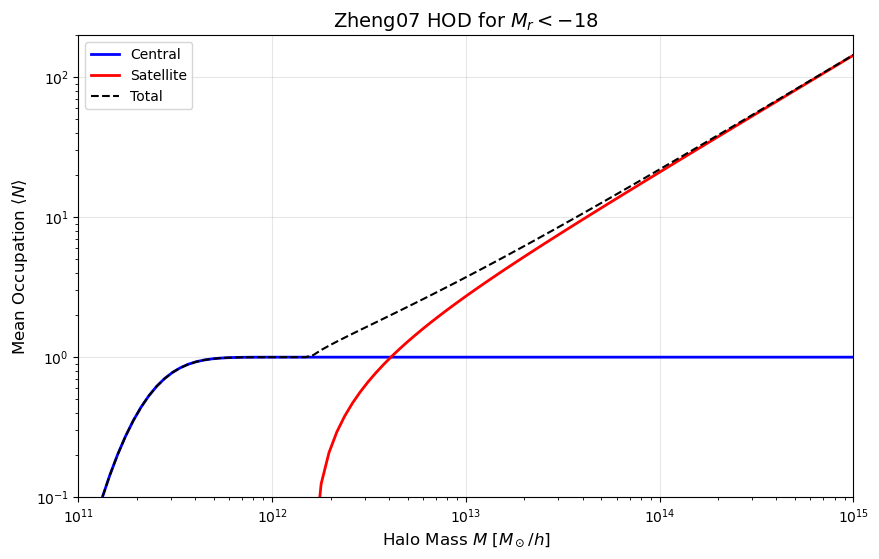

In [6]:
import matplotlib.pyplot as plt

# Generate test masses
test_masses = np.logspace(11, 15, 100)
N_cen_mean = []
N_sat_mean = []

HOD_sample=HOD_samples['SDSS18.0']
logM_min= HOD_sample['logM_min']
sigma_logM= HOD_sample['sigma_logM']
logM_0= HOD_sample['logM_0']
logM_1= HOD_sample['logM_1']
alpha= HOD_sample['alpha']
for M in test_masses:
    # Compute mean values (not sampled)
    logM = np.log10(M)
    mean_cen = 0.5 * (1 + erf((logM - logM_min) / sigma_logM))
    if M > 10**logM_0:
        mean_sat = ((M - 10**logM_0) / (10**logM_1))**alpha
    else:
        mean_sat = 0
    N_cen_mean.append(mean_cen)
    N_sat_mean.append(mean_sat)

plt.figure(figsize=(10,6))
plt.loglog(test_masses, N_cen_mean, 'b-', linewidth=2, label='Central')
plt.loglog(test_masses, N_sat_mean, 'r-', linewidth=2, label='Satellite')
plt.loglog(test_masses, np.array(N_cen_mean)+np.array(N_sat_mean), 
           'k--', label='Total')
plt.xlabel('Halo Mass $M$ [$M_\\odot/h$]', fontsize=12)
plt.ylabel('Mean Occupation $\\langle N \\rangle$', fontsize=12)
plt.ylim([1e-1,2e2])
plt.xlim([1e11,1e15])
plt.legend()
plt.grid(True, alpha=0.3)
plt.title('Zheng07 HOD for $M_r < -18$', fontsize=14)
plt.show()

### Richness

### BCG Luminosity

In [7]:
def lum_BCG_zheng07(M_BCG):
    L0_lumbcg= 2.8e9 #SDSS
    Mc_lumbcg=3.7e9
    k_lumbcg = 0.0255
    a_lumbcg = 29.78
    b_lumbcg =29.5
    Mratio = M_BCG/Mc_lumbcg
    return L0_lumbcg*Mratio**a_lumbcg*(1+Mratio**(b_lumbcg*k_lumbcg))**(-1/k_lumbcg)

print(f"{lum_BCG_zheng07(1e14):.2e}")

4.79e+10


### Satellite Luminosity Function

In [8]:
import numpy as np
from skypy.utils.random import schechter

def sample_schechter_luminosity(alpha, L_min, L_max, size=None, L_star=1e10):
    """
    Sample luminosities from a Schechter function.
    
    The Schechter function is defined as:
        phi(L) dL = phi* (L/L_star)^alpha * exp(-L/L_star) d(L/L_star)
    
    Parameters
    ----------
    alpha : float
        Faint-end slope parameter (typically negative, e.g., -1.2 to -1.8)
    L_min, L_max : float or array_like
        Minimum and maximum luminosities (in same units as L_star)
    size : int, optional
        Number of samples to draw. If None, returns a single sample.
    L_star : float or array_like, optional
        Characteristic luminosity (the "knee" of the function). Default 1e10.
    
    Returns
    -------
    L_sample : array_like
        Luminosities sampled from the Schechter function.
    
    Examples
    --------
    # Sample 1000 luminosities for red satellites (alpha = -1.8)
    L = sample_schechter_luminosity(alpha=-1.8, L_min=1e7, L_max=1e12, size=1000)
    
    # Convert to absolute magnitudes (M = -2.5*log10(L) + constant)
    M = -2.5 * np.log10(L) + M_sun_correction
    """
    # SkyPy's schechter function samples (L/L_star) with the given alpha
    # The PDF is proportional to (L/L_star)^alpha * exp(-L/L_star)
    L_over_Lstar = schechter(alpha=alpha, x_min=L_min/L_star, 
                             x_max=L_max/L_star, size=size)
    
    return L_over_Lstar * L_star


def sample_satellite_magnitudes(alpha, M_star, M_min, M_max, size=None):
    """
    Sample absolute magnitudes from a Schechter luminosity function.
    
    Parameters
    ----------
    alpha : float
        Faint-end slope (e.g., -1.8 for red satellites, -1.2 for blue satellites)
    M_star : float
        Characteristic absolute magnitude (the "knee")
    M_min, M_max : float
        Minimum and maximum absolute magnitudes (e.g., -22 and -14)
    size : int, optional
        Number of samples to draw.
    
    Returns
    -------
    M_sample : array_like
        Absolute magnitudes sampled from the Schechter function.
    
    Examples
    --------
    # Red satellites from Gao+2026 (alpha ~ -1.8, M_star ~ -21)
    M_red = sample_satellite_magnitudes(alpha=-1.8, M_star=-21.0, 
                                        M_min=-22, M_max=-14, size=500)
    
    # Blue satellites from Gao+2026 (alpha ~ -1.2)
    M_blue = sample_satellite_magnitudes(alpha=-1.2, M_star=-21.0,
                                         M_min=-22, M_max=-14, size=500)
    """
    # Convert magnitudes to luminosities
    # L/L_star = 10^(-0.4*(M - M_star))
    L_ratio_min = 10 ** (-0.4 * (M_max - M_star))
    L_ratio_max = 10 ** (-0.4 * (M_min - M_star))
    
    # Sample L/L_star from Schechter
    L_ratio = schechter(alpha=alpha, x_min=L_ratio_min, 
                        x_max=L_ratio_max, size=size)
    
    # Convert back to magnitudes
    M_sample = M_star - 2.5 * np.log10(L_ratio)
    
    return M_sample

In [9]:
# For red satellites (faint-end slope ~ -1.75 from Gao+2026)
M_red = sample_satellite_magnitudes(alpha=-1.75, M_star=-21.0, 
                                    M_min=-23, M_max=-14, size=1000)

# For blue satellites (slope ~ -1.22 from Gao+2026)
M_blue = sample_satellite_magnitudes(alpha=-1.22, M_star=-21.0,
                                     M_min=-23, M_max=-14, size=1000)

# For total satellites (Virgo Core value from Ferrarese+2016)
M_total = sample_satellite_magnitudes(alpha=-1.33, M_star=-21.2,
                                      M_min=-23, M_max=-12, size=1000)

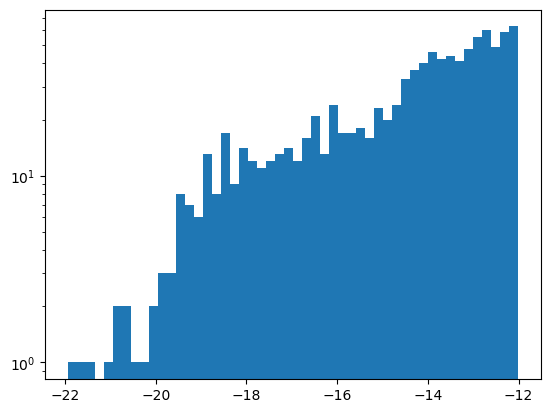

In [10]:
plt.hist(M_total,log=True,bins=50);

### Mass-Concetration Relation

In [11]:
def c_DuttonMaccio(z, m,c=1., h=1.):
  """Concentration from c(M) relation in Dutton & Maccio (2014).
  
  Code taken from Jes Ford on github.
  
  Parameters
  ----------
  z : float or array_like
      Redshift(s) of halos.
  m : float or array_like
      Mass(es) of halos (m200 definition), in units of solar masses.
  h : float, optional
      Hubble parameter. Default is from Planck13.
  Returns
  ----------
  ndarray
      Concentration values (c200) for halos.
  References
  ----------
  Calculation from Planck-based results of simulations presented in:
  A.A. Dutton & A.V. Maccio, "Cold dark matter haloes in the Planck era:
  evolution of structural parameters for Einasto and NFW profiles,"
  Monthly Notices of the Royal Astronomical Society, Volume 441, Issue 4,
  p.3359-3374, 2014.
  """


  a = 0.52 + 0.385 * np.exp(-0.617 * (z**1.21))  # EQ 10
  b = -0.101 + 0.026 * z                         # EQ 11

  logc200 = a + b * np.log10(m * h / (c*1e12))  # EQ 7 modified

  concentration = 10.**logc200
  return concentration

### Mass Richness Relation

In [12]:
#####mass obs
def mass_lambda_McClintock18(Lambda,z):
  #pivots
  log10Lambda0 = np.log10(40)
  log10z0 = np.log10(0.35)
  log10M0 = 14.489
  #scalings
  Flambda = 1.356
  Gz = -0.30
    
  mlog10M200 = log10M0 + Flambda*(np.log10(Lambda)-log10Lambda0) + Gz*(np.log10(z) - log10z0)
    
  return mlog10M200

### Environment Effects

## Forward Model